# modellen

kijken waarom de mlp zo overfit en of een extra laag iets doet. alles op bow, eindrun doen we in project1.ipynb

In [17]:
import sys
sys.path.append("..")

import numpy as np
import torch
import part1
from project1.data import load_data
from project1 import encoders, experiments

torch.manual_seed(0)


In [18]:
dataset, outcome_space = load_data(test_size=0.2, seed=0)
train_texts = dataset["train"]["text"]
pairs = list(zip(train_texts, dataset["train"]["label"]))

tokenizer = part1.experiment.train_tokenizer(train_texts, vocab_size=3000, min_frequency=5)
representations = {"bow": encoders.BagOfWords(tokenizer)}


In [19]:
def mlp(**args):
    return dict(model_option="mlp", smlp_args={"hidden_dim": 128, "num_epochs": 20, **args})

def summary(results):
    for name, runs in results.items():
        accuracies = [a for run in runs for a in run["accuracies"].values()]
        print(f"{name:32s} mean={np.mean(accuracies):.4f} std={np.std(accuracies):.4f}")


## regularisatie

train gaat naar 99%, val blijft op 55. eerst dropout en weight decay proberen

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 3.062 seconds
Dataloader done! Time taken: 0.088 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8648 | train acc: 0.3127 | val loss: 1.7173 | val acc: 0.4572
Epoch 02 | train loss: 1.4115 | train acc: 0.6068 | val loss: 1.4066 | val acc: 0.5328
Epoch 03 | train loss: 0.9734 | train acc: 0.7284 | val loss: 1.2997 | val acc: 0.5503
Epoch 04 | train loss: 0.6921 | train acc: 0.8185 | val loss: 1.2988 | val acc: 0.5528
Epoch 05 | train loss: 0.5140 | train acc: 0.8792 | val loss: 1.3416 | val acc: 0.5445
Epoch 06 | train loss: 0.3938 | train acc: 0.9135 | val loss: 1.4116 | val acc: 0.5395
Epoch 07 | train loss: 0.3016 | train acc: 0.9407 | val loss: 1.4972 | val acc: 0.5461
Epoch 08 | train loss: 0.2343 | train acc: 0.9603 | val loss: 1.5916 | val acc: 0.5370
Epoch 09 | train loss: 0.1852 | train acc: 0.9719 | val loss: 1.6820 | val acc: 0.5370
Epoch 10 | train loss: 0.1470 | train acc: 0.9796 | val loss: 1.7673 | val acc: 0.5328
Epoch 11 | train loss: 0.1212 | train acc: 0.9844 | val loss: 1.8559 | val acc: 0.5262
Epoch 12 | train loss: 0.0983 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8714 | train acc: 0.3109 | val loss: 1.7584 | val acc: 0.4190
Epoch 02 | train loss: 1.4346 | train acc: 0.5966 | val loss: 1.4531 | val acc: 0.5012
Epoch 03 | train loss: 0.9691 | train acc: 0.7401 | val loss: 1.3788 | val acc: 0.5179
Epoch 04 | train loss: 0.6797 | train acc: 0.8278 | val loss: 1.3707 | val acc: 0.5262
Epoch 05 | train loss: 0.5005 | train acc: 0.8842 | val loss: 1.4395 | val acc: 0.5079
Epoch 06 | train loss: 0.3756 | train acc: 0.9185 | val loss: 1.4903 | val acc: 0.5154
Epoch 07 | train loss: 0.2851 | train acc: 0.9472 | val loss: 1.5909 | val acc: 0.5037
Epoch 08 | train loss: 0.2211 | train acc: 0.9622 | val loss: 1.6965 | val acc: 0.5012
Epoch 09 | train loss: 0.1755 | train acc: 0.9746 | val loss: 1.7986 | val acc: 0.4963
Epoch 10 | train loss: 0.1392 | train acc: 0.9805 | val loss: 1.8618 | val acc: 0.4979
Epoch 11 | train loss: 0.1128 | train acc: 0.9859 | val loss: 1.9698 | val acc: 0.4913
Epoch 12 | train loss: 0.0941 | train acc: 

... (50 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8681 | train acc: 0.3110 | val loss: 1.7397 | val acc: 0.4351
Epoch 02 | train loss: 1.4368 | train acc: 0.5863 | val loss: 1.4173 | val acc: 0.5241
Epoch 03 | train loss: 0.9784 | train acc: 0.7283 | val loss: 1.3063 | val acc: 0.5441
Epoch 04 | train loss: 0.6990 | train acc: 0.8173 | val loss: 1.2893 | val acc: 0.5466
Epoch 05 | train loss: 0.5208 | train acc: 0.8736 | val loss: 1.3347 | val acc: 0.5491
Epoch 06 | train loss: 0.3946 | train acc: 0.9123 | val loss: 1.3925 | val acc: 0.5549
Epoch 07 | train loss: 0.3052 | train acc: 0.9418 | val loss: 1.4726 | val acc: 0.5549
Epoch 08 | train loss: 0.2375 | train acc: 0.9605 | val loss: 1.5405 | val acc: 0.5607
Epoch 09 | train loss: 0.1907 | train acc: 0.9690 | val loss: 1.6189 | val acc: 0.5549
Epoch 10 | train loss: 0.1511 | train acc: 0.9786 | val loss: 1.7020 | val acc: 0.5474
Epoch 11 | train loss: 0.1238 | train acc: 0.9850 | val loss: 1.7841 | val acc: 0.5524
Epoch 12 | train loss: 0.1015 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8578 | train acc: 0.3173 | val loss: 1.7282 | val acc: 0.4642
Epoch 02 | train loss: 1.4098 | train acc: 0.6129 | val loss: 1.4338 | val acc: 0.5200
Epoch 03 | train loss: 0.9722 | train acc: 0.7347 | val loss: 1.3172 | val acc: 0.5507
Epoch 04 | train loss: 0.6976 | train acc: 0.8185 | val loss: 1.3037 | val acc: 0.5516
Epoch 05 | train loss: 0.5166 | train acc: 0.8761 | val loss: 1.3556 | val acc: 0.5507
Epoch 06 | train loss: 0.3954 | train acc: 0.9131 | val loss: 1.4192 | val acc: 0.5358
Epoch 07 | train loss: 0.3089 | train acc: 0.9380 | val loss: 1.4895 | val acc: 0.5283
Epoch 08 | train loss: 0.2431 | train acc: 0.9555 | val loss: 1.5710 | val acc: 0.5266
Epoch 09 | train loss: 0.1966 | train acc: 0.9682 | val loss: 1.6586 | val acc: 0.5258
Epoch 10 | train loss: 0.1563 | train acc: 0.9761 | val loss: 1.7366 | val acc: 0.5208
Epoch 11 | train loss: 0.1290 | train acc: 0.9836 | val loss: 1.8261 | val acc: 0.5141
Epoch 12 | train loss: 0.1059 | train acc: 

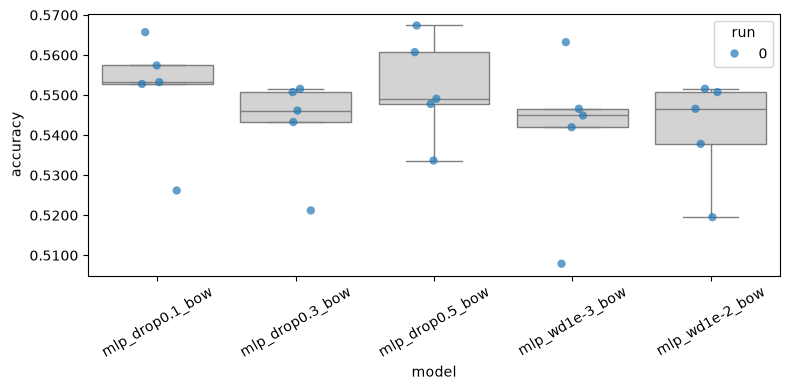

In [20]:
regularisation = {
    "mlp_drop0.1": mlp(dropout=0.1),
    "mlp_drop0.3": mlp(dropout=0.3),
    "mlp_drop0.5": mlp(dropout=0.5),
    "mlp_wd1e-3": mlp(weight_decay=1e-3),
    "mlp_wd1e-2": mlp(weight_decay=1e-2),
}
reg_results = experiments.run_experiments(
    representations, regularisation, pairs, outcome_space, results_dir="../results/models"
)
summary(reg_results)
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(reg_results))


## extremen

no effect 

wd 10 en 100 underfitting. dropout 0.1-0.8 is allemaal zo'n beetje hetzelfde

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.249 seconds
Dataloader done! Time taken: 0.052 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9081 | train acc: 0.2427 | val loss: 1.8224 | val acc: 0.4439
Epoch 02 | train loss: 1.6279 | train acc: 0.5063 | val loss: 1.5529 | val acc: 0.4988
Epoch 03 | train loss: 1.2564 | train acc: 0.6324 | val loss: 1.3687 | val acc: 0.5270
Epoch 04 | train loss: 0.9813 | train acc: 0.7236 | val loss: 1.2924 | val acc: 0.5320
Epoch 05 | train loss: 0.7808 | train acc: 0.7877 | val loss: 1.2736 | val acc: 0.5403
Epoch 06 | train loss: 0.6436 | train acc: 0.8262 | val loss: 1.2915 | val acc: 0.5436
Epoch 07 | train loss: 0.5421 | train acc: 0.8555 | val loss: 1.3111 | val acc: 0.5470
Epoch 08 | train loss: 0.4620 | train acc: 0.8819 | val loss: 1.3455 | val acc: 0.5436
Epoch 09 | train loss: 0.3864 | train acc: 0.9098 | val loss: 1.3867 | val acc: 0.5436
Epoch 10 | train loss: 0.3325 | train acc: 0.9293 | val loss: 1.4342 | val acc: 0.5353
Epoch 11 | train loss: 0.2871 | train acc: 0.9366 | val loss: 1.4773 | val acc: 0.5353
Epoch 12 | train loss: 0.2531 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9005 | train acc: 0.2535 | val loss: 1.8260 | val acc: 0.3840
Epoch 02 | train loss: 1.6248 | train acc: 0.5093 | val loss: 1.5841 | val acc: 0.4771
Epoch 03 | train loss: 1.2527 | train acc: 0.6297 | val loss: 1.4197 | val acc: 0.5021
Epoch 04 | train loss: 0.9695 | train acc: 0.7239 | val loss: 1.3493 | val acc: 0.5287
Epoch 05 | train loss: 0.7793 | train acc: 0.7848 | val loss: 1.3383 | val acc: 0.5287
Epoch 06 | train loss: 0.6415 | train acc: 0.8268 | val loss: 1.3484 | val acc: 0.5229
Epoch 07 | train loss: 0.5284 | train acc: 0.8640 | val loss: 1.3856 | val acc: 0.5162
Epoch 08 | train loss: 0.4589 | train acc: 0.8850 | val loss: 1.4169 | val acc: 0.5137
Epoch 09 | train loss: 0.3837 | train acc: 0.9079 | val loss: 1.4734 | val acc: 0.5096
Epoch 10 | train loss: 0.3307 | train acc: 0.9274 | val loss: 1.5098 | val acc: 0.5145
Epoch 11 | train loss: 0.2869 | train acc: 0.9374 | val loss: 1.5663 | val acc: 0.5145
Epoch 12 | train loss: 0.2556 | train acc: 

... (26 outputs left out)

  0%|          | 0/40 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9463 | train acc: 0.1605 | val loss: 1.9396 | val acc: 0.1697
Epoch 02 | train loss: 1.9293 | train acc: 0.1994 | val loss: 1.9294 | val acc: 0.2105
Epoch 03 | train loss: 1.9104 | train acc: 0.2486 | val loss: 1.9178 | val acc: 0.2512
Epoch 04 | train loss: 1.8907 | train acc: 0.3021 | val loss: 1.9041 | val acc: 0.2837
Epoch 05 | train loss: 1.8665 | train acc: 0.3509 | val loss: 1.8876 | val acc: 0.3295
Epoch 06 | train loss: 1.8391 | train acc: 0.3902 | val loss: 1.8678 | val acc: 0.3494
Epoch 07 | train loss: 1.8036 | train acc: 0.4459 | val loss: 1.8438 | val acc: 0.4043
Epoch 08 | train loss: 1.7679 | train acc: 0.4884 | val loss: 1.8166 | val acc: 0.4301
Epoch 09 | train loss: 1.7280 | train acc: 0.4988 | val loss: 1.7869 | val acc: 0.4526
Epoch 10 | train loss: 1.6842 | train acc: 0.5397 | val loss: 1.7570 | val acc: 0.4667
Epoch 11 | train loss: 1.6403 | train acc: 0.5653 | val loss: 1.7248 | val acc: 0.4750
Epoch 12 | train loss: 1.5948 | train acc: 

  0%|          | 0/40 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9473 | train acc: 0.1489 | val loss: 1.9406 | val acc: 0.1656
Epoch 02 | train loss: 1.9302 | train acc: 0.1965 | val loss: 1.9306 | val acc: 0.2180
Epoch 03 | train loss: 1.9128 | train acc: 0.2486 | val loss: 1.9199 | val acc: 0.2737
Epoch 04 | train loss: 1.8928 | train acc: 0.3081 | val loss: 1.9069 | val acc: 0.3186
Epoch 05 | train loss: 1.8660 | train acc: 0.3763 | val loss: 1.8901 | val acc: 0.3544
Epoch 06 | train loss: 1.8402 | train acc: 0.4006 | val loss: 1.8705 | val acc: 0.3844
Epoch 07 | train loss: 1.8072 | train acc: 0.4526 | val loss: 1.8471 | val acc: 0.4151
Epoch 08 | train loss: 1.7677 | train acc: 0.4854 | val loss: 1.8205 | val acc: 0.4384
Epoch 09 | train loss: 1.7262 | train acc: 0.5239 | val loss: 1.7909 | val acc: 0.4626
Epoch 10 | train loss: 1.6800 | train acc: 0.5472 | val loss: 1.7601 | val acc: 0.4667
Epoch 11 | train loss: 1.6368 | train acc: 0.5626 | val loss: 1.7294 | val acc: 0.4859
Epoch 12 | train loss: 1.5879 | train acc: 

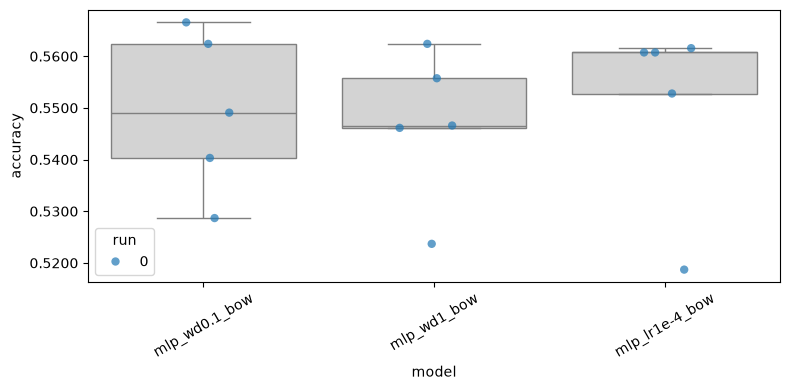

In [21]:
stronger = {
    "mlp_wd0.1": mlp(dropout=0.5, weight_decay=0.1),
    "mlp_wd1": mlp(dropout=0.5, weight_decay=1.0),
    "mlp_lr1e-4": mlp(dropout=0.5, learning_rate=1e-4, num_epochs=40),
}
strong_results = experiments.run_experiments(
    representations, stronger, pairs, outcome_space, results_dir="../results/models"
)
summary(strong_results)
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(strong_results))


  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.186 seconds
Dataloader done! Time taken: 0.053 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8670 | train acc: 0.3206 | val loss: 1.7194 | val acc: 0.4214
Epoch 02 | train loss: 1.3906 | train acc: 0.6078 | val loss: 1.3999 | val acc: 0.5112
Epoch 03 | train loss: 0.9254 | train acc: 0.7488 | val loss: 1.2990 | val acc: 0.5428
Epoch 04 | train loss: 0.6417 | train acc: 0.8432 | val loss: 1.3019 | val acc: 0.5478
Epoch 05 | train loss: 0.4632 | train acc: 0.8939 | val loss: 1.3750 | val acc: 0.5303
Epoch 06 | train loss: 0.3421 | train acc: 0.9305 | val loss: 1.4606 | val acc: 0.5370
Epoch 07 | train loss: 0.2557 | train acc: 0.9538 | val loss: 1.5432 | val acc: 0.5337
Epoch 08 | train loss: 0.1958 | train acc: 0.9713 | val loss: 1.6412 | val acc: 0.5353
Epoch 09 | train loss: 0.1500 | train acc: 0.9794 | val loss: 1.7429 | val acc: 0.5245
Epoch 10 | train loss: 0.1173 | train acc: 0.9873 | val loss: 1.8404 | val acc: 0.5195
Epoch 11 | train loss: 0.0931 | train acc: 0.9911 | val loss: 1.9268 | val acc: 0.5204
Epoch 12 | train loss: 0.0754 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8586 | train acc: 0.3333 | val loss: 1.7268 | val acc: 0.4214
Epoch 02 | train loss: 1.3740 | train acc: 0.6253 | val loss: 1.4313 | val acc: 0.5046
Epoch 03 | train loss: 0.9093 | train acc: 0.7669 | val loss: 1.3586 | val acc: 0.5079
Epoch 04 | train loss: 0.6297 | train acc: 0.8497 | val loss: 1.4241 | val acc: 0.5104
Epoch 05 | train loss: 0.4571 | train acc: 0.8950 | val loss: 1.4560 | val acc: 0.5121
Epoch 06 | train loss: 0.3381 | train acc: 0.9310 | val loss: 1.5626 | val acc: 0.5162
Epoch 07 | train loss: 0.2518 | train acc: 0.9559 | val loss: 1.6645 | val acc: 0.5037
Epoch 08 | train loss: 0.1935 | train acc: 0.9694 | val loss: 1.7609 | val acc: 0.4938
Epoch 09 | train loss: 0.1498 | train acc: 0.9813 | val loss: 1.8646 | val acc: 0.4913
Epoch 10 | train loss: 0.1183 | train acc: 0.9865 | val loss: 1.9550 | val acc: 0.4913
Epoch 11 | train loss: 0.0942 | train acc: 0.9902 | val loss: 2.0660 | val acc: 0.4871
Epoch 12 | train loss: 0.0774 | train acc: 

... (50 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9449 | train acc: 0.1584 | val loss: 1.9453 | val acc: 0.1739
Epoch 02 | train loss: 1.9442 | train acc: 0.2031 | val loss: 1.9430 | val acc: 0.2313
Epoch 03 | train loss: 1.9417 | train acc: 0.2200 | val loss: 1.9425 | val acc: 0.1722
Epoch 04 | train loss: 1.9417 | train acc: 0.1969 | val loss: 1.9426 | val acc: 0.1464
Epoch 05 | train loss: 1.9424 | train acc: 0.1996 | val loss: 1.9428 | val acc: 0.1406
Epoch 06 | train loss: 1.9425 | train acc: 0.1906 | val loss: 1.9434 | val acc: 0.1398
Epoch 07 | train loss: 1.9429 | train acc: 0.1875 | val loss: 1.9431 | val acc: 0.1747
Epoch 08 | train loss: 1.9420 | train acc: 0.1844 | val loss: 1.9429 | val acc: 0.2038
Epoch 09 | train loss: 1.9423 | train acc: 0.1832 | val loss: 1.9431 | val acc: 0.1880
Epoch 10 | train loss: 1.9420 | train acc: 0.1742 | val loss: 1.9428 | val acc: 0.2022
Epoch 11 | train loss: 1.9421 | train acc: 0.1925 | val loss: 1.9422 | val acc: 0.2146
Epoch 12 | train loss: 1.9418 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9456 | train acc: 0.1861 | val loss: 1.9453 | val acc: 0.1439
Epoch 02 | train loss: 1.9439 | train acc: 0.1942 | val loss: 1.9435 | val acc: 0.1348
Epoch 03 | train loss: 1.9419 | train acc: 0.1850 | val loss: 1.9427 | val acc: 0.2546
Epoch 04 | train loss: 1.9421 | train acc: 0.2335 | val loss: 1.9430 | val acc: 0.1498
Epoch 05 | train loss: 1.9419 | train acc: 0.1896 | val loss: 1.9427 | val acc: 0.1764
Epoch 06 | train loss: 1.9424 | train acc: 0.1929 | val loss: 1.9434 | val acc: 0.1506
Epoch 07 | train loss: 1.9427 | train acc: 0.1881 | val loss: 1.9431 | val acc: 0.1872
Epoch 08 | train loss: 1.9424 | train acc: 0.1890 | val loss: 1.9435 | val acc: 0.1406
Epoch 09 | train loss: 1.9423 | train acc: 0.1850 | val loss: 1.9428 | val acc: 0.1356
Epoch 10 | train loss: 1.9418 | train acc: 0.1751 | val loss: 1.9430 | val acc: 0.1448
Epoch 11 | train loss: 1.9428 | train acc: 0.2023 | val loss: 1.9431 | val acc: 0.1348
Epoch 12 | train loss: 1.9421 | train acc: 

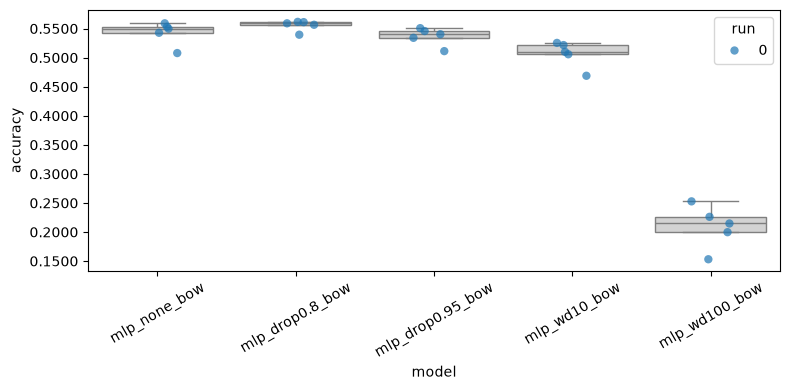

In [22]:
extremes = {
    "mlp_none": mlp(dropout=0.0, weight_decay=0.0),
    "mlp_drop0.8": mlp(dropout=0.8, weight_decay=1e-4),
    "mlp_drop0.95": mlp(dropout=0.95, weight_decay=1e-4),
    "mlp_wd10": mlp(dropout=0.5, weight_decay=10.0),
    "mlp_wd100": mlp(dropout=0.5, weight_decay=100.0),
}
extreme_results = experiments.run_experiments(
    representations, extremes, pairs, outcome_space, results_dir="../results/models"
)
summary(extreme_results)
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(extreme_results))


## kleiner model?



  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.237 seconds
Dataloader done! Time taken: 0.053 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9335 | train acc: 0.1817 | val loss: 1.8977 | val acc: 0.2502
Epoch 02 | train loss: 1.8300 | train acc: 0.3327 | val loss: 1.8073 | val acc: 0.3267
Epoch 03 | train loss: 1.7081 | train acc: 0.4167 | val loss: 1.7194 | val acc: 0.3807
Epoch 04 | train loss: 1.5776 | train acc: 0.5088 | val loss: 1.6337 | val acc: 0.4389
Epoch 05 | train loss: 1.4440 | train acc: 0.5731 | val loss: 1.5535 | val acc: 0.4796
Epoch 06 | train loss: 1.3172 | train acc: 0.6203 | val loss: 1.4856 | val acc: 0.4988
Epoch 07 | train loss: 1.2042 | train acc: 0.6498 | val loss: 1.4304 | val acc: 0.5137
Epoch 08 | train loss: 1.1063 | train acc: 0.6854 | val loss: 1.3913 | val acc: 0.5320
Epoch 09 | train loss: 1.0186 | train acc: 0.7145 | val loss: 1.3659 | val acc: 0.5303
Epoch 10 | train loss: 0.9406 | train acc: 0.7357 | val loss: 1.3391 | val acc: 0.5370
Epoch 11 | train loss: 0.8742 | train acc: 0.7515 | val loss: 1.3245 | val acc: 0.5420
Epoch 12 | train loss: 0.8174 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9314 | train acc: 0.1955 | val loss: 1.8984 | val acc: 0.2377
Epoch 02 | train loss: 1.8233 | train acc: 0.3313 | val loss: 1.8094 | val acc: 0.3308
Epoch 03 | train loss: 1.6804 | train acc: 0.4483 | val loss: 1.7271 | val acc: 0.3757
Epoch 04 | train loss: 1.5330 | train acc: 0.5192 | val loss: 1.6444 | val acc: 0.4015
Epoch 05 | train loss: 1.4040 | train acc: 0.5648 | val loss: 1.5875 | val acc: 0.4256
Epoch 06 | train loss: 1.2934 | train acc: 0.6078 | val loss: 1.5403 | val acc: 0.4472
Epoch 07 | train loss: 1.1994 | train acc: 0.6338 | val loss: 1.5064 | val acc: 0.4630
Epoch 08 | train loss: 1.1181 | train acc: 0.6590 | val loss: 1.4847 | val acc: 0.4688
Epoch 09 | train loss: 1.0339 | train acc: 0.6902 | val loss: 1.4683 | val acc: 0.4746
Epoch 10 | train loss: 0.9720 | train acc: 0.7120 | val loss: 1.4591 | val acc: 0.4771
Epoch 11 | train loss: 0.9085 | train acc: 0.7382 | val loss: 1.4484 | val acc: 0.4796
Epoch 12 | train loss: 0.8632 | train acc: 

... (38 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8923 | train acc: 0.2557 | val loss: 1.7973 | val acc: 0.4293
Epoch 02 | train loss: 1.5617 | train acc: 0.5721 | val loss: 1.5194 | val acc: 0.5083
Epoch 03 | train loss: 1.1710 | train acc: 0.6811 | val loss: 1.3593 | val acc: 0.5408
Epoch 04 | train loss: 0.8950 | train acc: 0.7607 | val loss: 1.3004 | val acc: 0.5516
Epoch 05 | train loss: 0.7162 | train acc: 0.8123 | val loss: 1.2881 | val acc: 0.5557
Epoch 06 | train loss: 0.5751 | train acc: 0.8576 | val loss: 1.3080 | val acc: 0.5499
Epoch 07 | train loss: 0.4720 | train acc: 0.8881 | val loss: 1.3486 | val acc: 0.5582
Epoch 08 | train loss: 0.3959 | train acc: 0.9125 | val loss: 1.3929 | val acc: 0.5624
Epoch 09 | train loss: 0.3308 | train acc: 0.9289 | val loss: 1.4403 | val acc: 0.5591
Epoch 10 | train loss: 0.2753 | train acc: 0.9489 | val loss: 1.5028 | val acc: 0.5582
Epoch 11 | train loss: 0.2347 | train acc: 0.9586 | val loss: 1.5675 | val acc: 0.5549
Epoch 12 | train loss: 0.2020 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8890 | train acc: 0.2694 | val loss: 1.7965 | val acc: 0.4035
Epoch 02 | train loss: 1.5528 | train acc: 0.5622 | val loss: 1.5336 | val acc: 0.5042
Epoch 03 | train loss: 1.1629 | train acc: 0.6936 | val loss: 1.3785 | val acc: 0.5416
Epoch 04 | train loss: 0.8851 | train acc: 0.7655 | val loss: 1.3046 | val acc: 0.5383
Epoch 05 | train loss: 0.6948 | train acc: 0.8243 | val loss: 1.2930 | val acc: 0.5524
Epoch 06 | train loss: 0.5586 | train acc: 0.8636 | val loss: 1.3109 | val acc: 0.5458
Epoch 07 | train loss: 0.4573 | train acc: 0.8933 | val loss: 1.3592 | val acc: 0.5474
Epoch 08 | train loss: 0.3792 | train acc: 0.9168 | val loss: 1.3937 | val acc: 0.5283
Epoch 09 | train loss: 0.3156 | train acc: 0.9349 | val loss: 1.4701 | val acc: 0.5358
Epoch 10 | train loss: 0.2659 | train acc: 0.9503 | val loss: 1.5104 | val acc: 0.5241
Epoch 11 | train loss: 0.2227 | train acc: 0.9597 | val loss: 1.5775 | val acc: 0.5275
Epoch 12 | train loss: 0.1915 | train acc: 

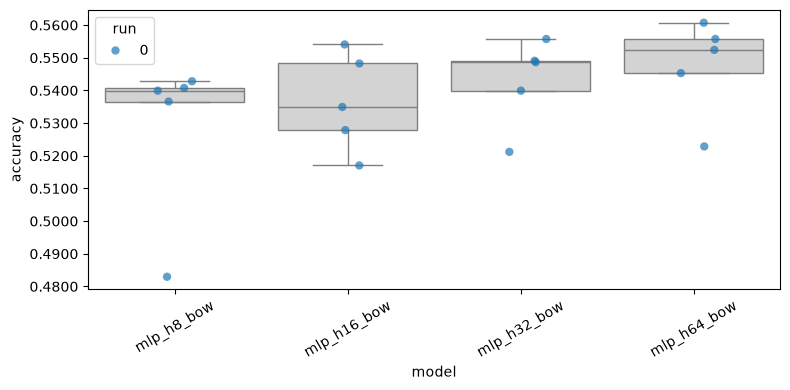

In [23]:
smaller = {f"mlp_h{h}": mlp(hidden_dim=h, dropout=0.1) for h in [8, 16, 32, 64]}
small_results = experiments.run_experiments(
    representations, smaller, pairs, outcome_space, results_dir="../results/models"
)
summary(small_results)
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(small_results))


## extra laag

met dropout 0.5 en wd 0.1, en patience zodat hij stopt als val loss niet meer daalt

helpt niet, mlp2 zit ~1% onder de gewone mlp. model overfit al dus meer capaciteit doet niks. mlp2_128_64 als derde model houden

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.249 seconds
Dataloader done! Time taken: 0.053 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9046 | train acc: 0.2377 | val loss: 1.8197 | val acc: 0.4372
Epoch 02 | train loss: 1.6406 | train acc: 0.4926 | val loss: 1.5572 | val acc: 0.4979
Epoch 03 | train loss: 1.2784 | train acc: 0.6230 | val loss: 1.3863 | val acc: 0.5511
Epoch 04 | train loss: 0.9827 | train acc: 0.7228 | val loss: 1.2926 | val acc: 0.5528
Epoch 05 | train loss: 0.7977 | train acc: 0.7765 | val loss: 1.2767 | val acc: 0.5544
Epoch 06 | train loss: 0.6535 | train acc: 0.8235 | val loss: 1.2841 | val acc: 0.5470
Epoch 07 | train loss: 0.5488 | train acc: 0.8549 | val loss: 1.3037 | val acc: 0.5420
Epoch 08 | train loss: 0.4598 | train acc: 0.8879 | val loss: 1.3390 | val acc: 0.5486
Epoch 09 | train loss: 0.3922 | train acc: 0.9050 | val loss: 1.3838 | val acc: 0.5461
Epoch 10 | train loss: 0.3384 | train acc: 0.9256 | val loss: 1.4229 | val acc: 0.5503
Epoch 11 | train loss: 0.2999 | train acc: 0.9341 | val loss: 1.4577 | val acc: 0.5503
Epoch 12 | train loss: 0.2527 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9072 | train acc: 0.2545 | val loss: 1.8412 | val acc: 0.3932
Epoch 02 | train loss: 1.6389 | train acc: 0.5014 | val loss: 1.5840 | val acc: 0.4821
Epoch 03 | train loss: 1.2586 | train acc: 0.6386 | val loss: 1.4292 | val acc: 0.5046
Epoch 04 | train loss: 0.9630 | train acc: 0.7274 | val loss: 1.3577 | val acc: 0.5287
Epoch 05 | train loss: 0.7802 | train acc: 0.7785 | val loss: 1.3344 | val acc: 0.5395
Epoch 06 | train loss: 0.6318 | train acc: 0.8307 | val loss: 1.3585 | val acc: 0.5212
Epoch 07 | train loss: 0.5263 | train acc: 0.8665 | val loss: 1.3635 | val acc: 0.5303
Epoch 08 | train loss: 0.4387 | train acc: 0.8931 | val loss: 1.4017 | val acc: 0.5345
Epoch 09 | train loss: 0.3776 | train acc: 0.9098 | val loss: 1.4566 | val acc: 0.5145
Epoch 10 | train loss: 0.3327 | train acc: 0.9253 | val loss: 1.4955 | val acc: 0.5187
Epoch 11 | train loss: 0.2835 | train acc: 0.9374 | val loss: 1.5329 | val acc: 0.5162
Epoch 12 | train loss: 0.2478 | train acc: 

... (2 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9023 | train acc: 0.2476 | val loss: 1.8209 | val acc: 0.4085
Epoch 02 | train loss: 1.6338 | train acc: 0.4981 | val loss: 1.5513 | val acc: 0.5125
Epoch 03 | train loss: 1.2626 | train acc: 0.6252 | val loss: 1.3816 | val acc: 0.5225
Epoch 04 | train loss: 0.9993 | train acc: 0.7042 | val loss: 1.2974 | val acc: 0.5632
Epoch 05 | train loss: 0.8019 | train acc: 0.7736 | val loss: 1.2685 | val acc: 0.5724
Epoch 06 | train loss: 0.6608 | train acc: 0.8212 | val loss: 1.2750 | val acc: 0.5691
Epoch 07 | train loss: 0.5569 | train acc: 0.8474 | val loss: 1.2929 | val acc: 0.5549
Epoch 08 | train loss: 0.4683 | train acc: 0.8832 | val loss: 1.3300 | val acc: 0.5674
Epoch 09 | train loss: 0.4092 | train acc: 0.8983 | val loss: 1.3501 | val acc: 0.5616
Epoch 10 | train loss: 0.3469 | train acc: 0.9193 | val loss: 1.3966 | val acc: 0.5582
Epoch 11 | train loss: 0.3065 | train acc: 0.9304 | val loss: 1.4403 | val acc: 0.5566
Epoch 12 | train loss: 0.2666 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8970 | train acc: 0.2553 | val loss: 1.8197 | val acc: 0.4043
Epoch 02 | train loss: 1.6153 | train acc: 0.5162 | val loss: 1.5651 | val acc: 0.5017
Epoch 03 | train loss: 1.2586 | train acc: 0.6301 | val loss: 1.3958 | val acc: 0.5275
Epoch 04 | train loss: 0.9879 | train acc: 0.7191 | val loss: 1.3314 | val acc: 0.5408
Epoch 05 | train loss: 0.8019 | train acc: 0.7786 | val loss: 1.2953 | val acc: 0.5507
Epoch 06 | train loss: 0.6542 | train acc: 0.8233 | val loss: 1.2954 | val acc: 0.5507
Epoch 07 | train loss: 0.5512 | train acc: 0.8565 | val loss: 1.3067 | val acc: 0.5449
Epoch 08 | train loss: 0.4700 | train acc: 0.8842 | val loss: 1.3378 | val acc: 0.5416
Epoch 09 | train loss: 0.4040 | train acc: 0.9019 | val loss: 1.3684 | val acc: 0.5366
Epoch 10 | train loss: 0.3456 | train acc: 0.9166 | val loss: 1.4153 | val acc: 0.5416
Epoch 11 | train loss: 0.3021 | train acc: 0.9314 | val loss: 1.4448 | val acc: 0.5383
Epoch 12 | train loss: 0.2643 | train acc: 

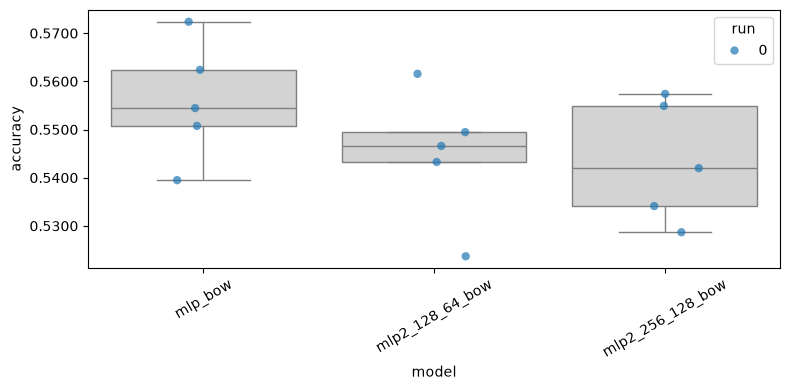

In [24]:
BEST_DROPOUT = 0.5
BEST_WEIGHT_DECAY = 0.1

shared = dict(dropout=BEST_DROPOUT, weight_decay=BEST_WEIGHT_DECAY)

candidates = {
    "mlp": mlp(**shared),
    "mlp2_128_64": dict(model_option="mlp2", mlp2_args=dict(hidden_dim=128, second_hidden_dim=64, patience=3, **shared)),
    "mlp2_256_128": dict(model_option="mlp2", mlp2_args=dict(hidden_dim=256, second_hidden_dim=128, patience=3, **shared)),
}
arch_results = experiments.run_experiments(
    representations, candidates, pairs, outcome_space, results_dir="../results/models"
)
summary(arch_results)
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(arch_results))


## tokenizer changes

In [25]:
for vocab_size, min_frequency in [(1000, 5), (3000, 2), (3000, 5), (5000, 5)]:
    name = f"bow_v{vocab_size}_mf{min_frequency}"
    tok = part1.experiment.train_tokenizer(train_texts, vocab_size=vocab_size, min_frequency=min_frequency)
    print(name, "werkelijke vocabulaire:", len(tok.get_vocab()))
    summary(experiments.run_experiments(
        {name: encoders.BagOfWords(tok)}, {"mlp": mlp(**shared)},
        pairs, outcome_space, results_dir="../results/models"
    ))





bow_v1000_mf5 werkelijke vocabulaire: 1000


  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.819 seconds
Dataloader done! Time taken: 0.031 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9106 | train acc: 0.2254 | val loss: 1.8316 | val acc: 0.3899
Epoch 02 | train loss: 1.7160 | train acc: 0.4146 | val loss: 1.6170 | val acc: 0.4746
Epoch 03 | train loss: 1.4557 | train acc: 0.5213 | val loss: 1.4458 | val acc: 0.5212
Epoch 04 | train loss: 1.2464 | train acc: 0.5908 | val loss: 1.3602 | val acc: 0.5320
Epoch 05 | train loss: 1.1068 | train acc: 0.6409 | val loss: 1.3295 | val acc: 0.5387
Epoch 06 | train loss: 0.9945 | train acc: 0.6781 | val loss: 1.3132 | val acc: 0.5461
Epoch 07 | train loss: 0.9094 | train acc: 0.7045 | val loss: 1.3044 | val acc: 0.5387
Epoch 08 | train loss: 0.8354 | train acc: 0.7347 | val loss: 1.3049 | val acc: 0.5445
Epoch 09 | train loss: 0.7843 | train acc: 0.7490 | val loss: 1.3217 | val acc: 0.5436
Epoch 10 | train loss: 0.7111 | train acc: 0.7779 | val loss: 1.3351 | val acc: 0.5520
Epoch 11 | train loss: 0.6759 | train acc: 0.7916 | val loss: 1.3568 | val acc: 0.5511
Epoch 12 | train loss: 0.6389 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

... (39 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8966 | train acc: 0.2620 | val loss: 1.8152 | val acc: 0.4393
Epoch 02 | train loss: 1.5947 | train acc: 0.5314 | val loss: 1.5413 | val acc: 0.5175
Epoch 03 | train loss: 1.2006 | train acc: 0.6742 | val loss: 1.3764 | val acc: 0.5466
Epoch 04 | train loss: 0.9002 | train acc: 0.7605 | val loss: 1.2975 | val acc: 0.5691
Epoch 05 | train loss: 0.6752 | train acc: 0.8324 | val loss: 1.2805 | val acc: 0.5757
Epoch 06 | train loss: 0.5410 | train acc: 0.8680 | val loss: 1.3020 | val acc: 0.5691
Epoch 07 | train loss: 0.4240 | train acc: 0.9044 | val loss: 1.3265 | val acc: 0.5715
Epoch 08 | train loss: 0.3502 | train acc: 0.9243 | val loss: 1.3670 | val acc: 0.5699
Epoch 09 | train loss: 0.2860 | train acc: 0.9428 | val loss: 1.4113 | val acc: 0.5624
Epoch 10 | train loss: 0.2424 | train acc: 0.9555 | val loss: 1.4522 | val acc: 0.5682
Epoch 11 | train loss: 0.1984 | train acc: 0.9663 | val loss: 1.5073 | val acc: 0.5574
Epoch 12 | train loss: 0.1710 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8991 | train acc: 0.2613 | val loss: 1.8207 | val acc: 0.3985
Epoch 02 | train loss: 1.6048 | train acc: 0.5314 | val loss: 1.5617 | val acc: 0.5008
Epoch 03 | train loss: 1.2046 | train acc: 0.6649 | val loss: 1.3699 | val acc: 0.5316
Epoch 04 | train loss: 0.8850 | train acc: 0.7676 | val loss: 1.2985 | val acc: 0.5557
Epoch 05 | train loss: 0.6780 | train acc: 0.8285 | val loss: 1.2673 | val acc: 0.5524
Epoch 06 | train loss: 0.5224 | train acc: 0.8773 | val loss: 1.2745 | val acc: 0.5532
Epoch 07 | train loss: 0.4195 | train acc: 0.9064 | val loss: 1.3101 | val acc: 0.5458
Epoch 08 | train loss: 0.3444 | train acc: 0.9258 | val loss: 1.3350 | val acc: 0.5483
Epoch 09 | train loss: 0.2815 | train acc: 0.9447 | val loss: 1.3734 | val acc: 0.5491
Epoch 10 | train loss: 0.2299 | train acc: 0.9584 | val loss: 1.4089 | val acc: 0.5524
Epoch 11 | train loss: 0.1982 | train acc: 0.9686 | val loss: 1.4554 | val acc: 0.5499
Epoch 12 | train loss: 0.1617 | train acc: 

## final setting

In [26]:
architectures = {
    "logistic": dict(model_option="logistic", loglin_args={"max_iter": 200}),
    "mlp": mlp(**shared),
    "mlp2": candidates["mlp2_128_64"],
}
